<a href="https://colab.research.google.com/github/gabrielangelocalderon-beep/IS110-repo_Calderon/blob/main/Copy_of_ML_Workbook_Wisconsin_Diagnostic.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Workbook Exercise: Breast Cancer Diagnosis — An End-to-End Classification Project

**Course:** Machine Learning / Applied AI  **Level:** Intermediate  **Estimated time:** 2 hours

**Learning objectives.** By the end of this workbook you will be able to:
1. Frame a real-world problem as a supervised learning task.
2. Summarize and visualize a dataset to understand its structure before modeling.
3. Clean data, select informative features and apply appropriate transforms.
4. Build a leak-free test harness and spot-check several algorithms.
5. Improve accuracy through tuning and ensembles, then report honest test results.

**How to use this workbook.** Run the cells in order. Wherever you see `# TODO`, replace the `...` with your own code (hints are given). Cells marked ✏️ ask for a written answer: double-click to edit. Do not look at the answer key until you have tried each exercise.

**Outline**
- A. Problem Definition
- B. Summarize and Analyze Data
- C. Prepare Data
- D. Evaluate Algorithm
- E. Improve Accuracy



## Before you begin

> First, make a copy of this notebook so that you can make changes as you please.
> Run and edit the copy instead of this original notebook.

> To copy this notebook, go to `File|Save a Copy to Drive`.

**Gentle Reminder**
> Once finish, Kindly `push` this notebook to your GitHub repo.**

---
## A. Problem Definition

### A.1 Brief Description
The **Breast Cancer Wisconsin (Diagnostic)** dataset contains measurements computed from digitized images of fine-needle aspirates (FNA) of breast masses. Each row describes the characteristics of the cell nuclei present in one image.

- **569 instances**, **30 numeric features**, **1 binary target**
- Features are 10 nucleus measurements (radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry, fractal dimension), each reported as the **mean**, the **standard error** and the **worst** (largest) value.
- Target: `0` = malignant, `1` = benign.

### A.2 Problem Statement
✏️ **Exercise A.1.** In 3–4 sentences, write a problem statement in your own words. Include: (a) the prediction task, (b) the input data, (c) the type of learning problem, (d) which kind of error is more costly and why, and (e) how you will judge success.

> **Your answer:** *(double-click to edit)*

The goal of this supervised binary classification problem is to predict whether a breast mass is malignant or benign. The model will make these predictions using 30 numeric features collected from 569 patient instances. A false negative error is the most costly because missing a cancer diagnosis can be life-threatening, so success will be judged by achieving a high recall score to minimize this mistake.

### A.3 Load Packages
**Exercise A.2.** The imports below are mostly done. Add the classifier imports you will need in Parts C–E.

In [72]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [73]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_val_score, cross_validate, GridSearchCV)
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif, RFE
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, classification_report,
                             ConfusionMatrixDisplay, make_scorer, recall_score)

# TODO: import LogisticRegression, LinearDiscriminantAnalysis, KNeighborsClassifier, DecisionTreeClassifier, GaussianNB, SVC, RandomForest, ExtraTrees, GradientBoosting, AdaBoost and VotingClassifier
...

try:
    display
except NameError:
    display = print

In [74]:
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier, AdaBoostClassifier, VotingClassifier

print("Classifiers imported successfully.")

Classifiers imported successfully.


### A.4 Load Dataset
**Exercise A.3.** Load the data into a DataFrame named `df` (hint: `load_breast_cancer(as_frame=True)`).



> `url = [https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic]`

In [75]:
# TODO: load the dataset and copy its DataFrame into df
data = load_breast_cancer(as_frame=True)
df = data.frame

print("Rows, columns:", df.shape)
print("Classes:", list(data.target_names), "-> 0 = malignant, 1 = benign")

Rows, columns: (569, 31)
Classes: [np.str_('malignant'), np.str_('benign')] -> 0 = malignant, 1 = benign


---
## B. Summarize and Analyze Data

### B.1 Descriptive Statistics
**Exercise B.1.** Inspect the dataset's dimensions, data types and the first rows.

In [76]:
print("Shape of dataset:", df.shape)
print("\nData type counts:")
print(df.dtypes.value_counts())
print("\nFirst 5 rows of the dataset:")
display(df.head())

Shape of dataset: (569, 31)

Data type counts:
float64    30
int64       1
Name: count, dtype: int64

First 5 rows of the dataset:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [77]:
counts = df['target'].value_counts()
proportions = df['target'].value_counts(normalize=True) * 100
class_balance = pd.DataFrame({'Count': counts, 'Percentage (%)': proportions})
class_balance.index = class_balance.index.map({0: 'Malignant (0)', 1: 'Benign (1)'})
display(class_balance)

,Count,Percentage (%)
target,,
Benign (1),357,62.741652
Malignant (0),212,37.258348


In [78]:
summary_stats = df.describe().T
display(summary_stats)

skewness = df.skew().sort_values(ascending=False)
print("\nTop 10 most skewed features:")
display(skewness.head(10))

,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744



Top 10 most skewed features:


,0
area error,5.447186
concavity error,5.110463
fractal dimension error,3.923969
perimeter error,3.443615
radius error,3.088612
smoothness error,2.314450
symmetry error,2.195133
compactness error,1.902221
worst area,1.859373
worst fractal dimension,1.662579


In [79]:
correlations = df.corr()['target'].sort_values()
print("Top 5 most negatively correlated features with target:")
display(correlations.head(5))
print("\nTop 5 most positively correlated features with target:")
display(correlations.tail(6).iloc[:-1])

Top 5 most negatively correlated features with target:


,target
worst concave points,-0.793566
worst perimeter,-0.782914
mean concave points,-0.776614
worst radius,-0.776454
mean perimeter,-0.742636



Top 5 most positively correlated features with target:


,target
fractal dimension error,-0.077972
symmetry error,0.006522
texture error,0.008303
mean fractal dimension,0.012838
smoothness error,0.067016


In [80]:
print("Shape of dataset:", df.shape)
print("\nData type counts:")
print(df.dtypes.value_counts())
print("\nFirst 5 rows of the dataset:")
display(df.head())

Shape of dataset: (569, 31)

Data type counts:
float64    30
int64       1
Name: count, dtype: int64

First 5 rows of the dataset:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


**Exercise B.2.** Check for class imbalance. Print the count and the proportion of each class.

In [81]:
counts = df['target'].value_counts()
proportions = df['target'].value_counts(normalize=True) * 100
class_balance = pd.DataFrame({'Count': counts, 'Percentage (%)': proportions})
class_balance.index = class_balance.index.map({0: 'Malignant (0)', 1: 'Benign (1)'})
display(class_balance)

,Count,Percentage (%)
target,,
Benign (1),357,62.741652
Malignant (0),212,37.258348


**Exercise B.3.** Produce summary statistics (transposed so features are rows) and list the 10 most skewed features.

In [82]:
summary_stats = df.describe().T
display(summary_stats)

skewness = df.skew().sort_values(ascending=False)
print("\nTop 10 most skewed features:")
display(skewness.head(10))

,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744



Top 10 most skewed features:


,0
area error,5.447186
concavity error,5.110463
fractal dimension error,3.923969
perimeter error,3.443615
radius error,3.088612
smoothness error,2.314450
symmetry error,2.195133
compactness error,1.902221
worst area,1.859373
worst fractal dimension,1.662579


**Exercise B.4.** Compute the correlation of every feature with the target and show the 5 most negative and 5 most positive.

In [83]:
correlations = df.corr()['target'].sort_values()
print("Top 5 most negatively correlated features with target:")
display(correlations.head(5))
print("\nTop 5 most positively correlated features with target:")
display(correlations.tail(6).iloc[:-1])

Top 5 most negatively correlated features with target:


,target
worst concave points,-0.793566
worst perimeter,-0.782914
mean concave points,-0.776614
worst radius,-0.776454
mean perimeter,-0.742636



Top 5 most positively correlated features with target:


,target
fractal dimension error,-0.077972
symmetry error,0.006522
texture error,0.008303
mean fractal dimension,0.012838
smoothness error,0.067016


✏️ **Question B.5.** What do the class proportions and the skewness tell you about the choice of evaluation metric and the need for transforms?

> **Your answer:**
> 1. **Class Proportions (~63% Benign vs ~37% Malignant):** The dataset is moderately imbalanced. While accuracy is still useful, it alone is insufficient because predicting the majority class would yield ~63% accuracy. We need to focus on metrics like **Recall** (or sensitivity) and the **F1-score**, particularly for the malignant class (0), because missing a positive cancer diagnosis (a False Negative) is highly costly.
> 2. **Skewness:** Several features (such as `area error` and `concavity error` with skewness values > 5) are highly right-skewed. Highly skewed features can negatively impact linear models and distance-based estimators. This indicates we should consider applying power transforms (like Log or Box-Cox) or robust scaling/standardization to mitigate the effect of extreme values.

### B.2 Data Visualization

**Exercise B.6 (univariate).** Plot histograms of the ten `mean` features.

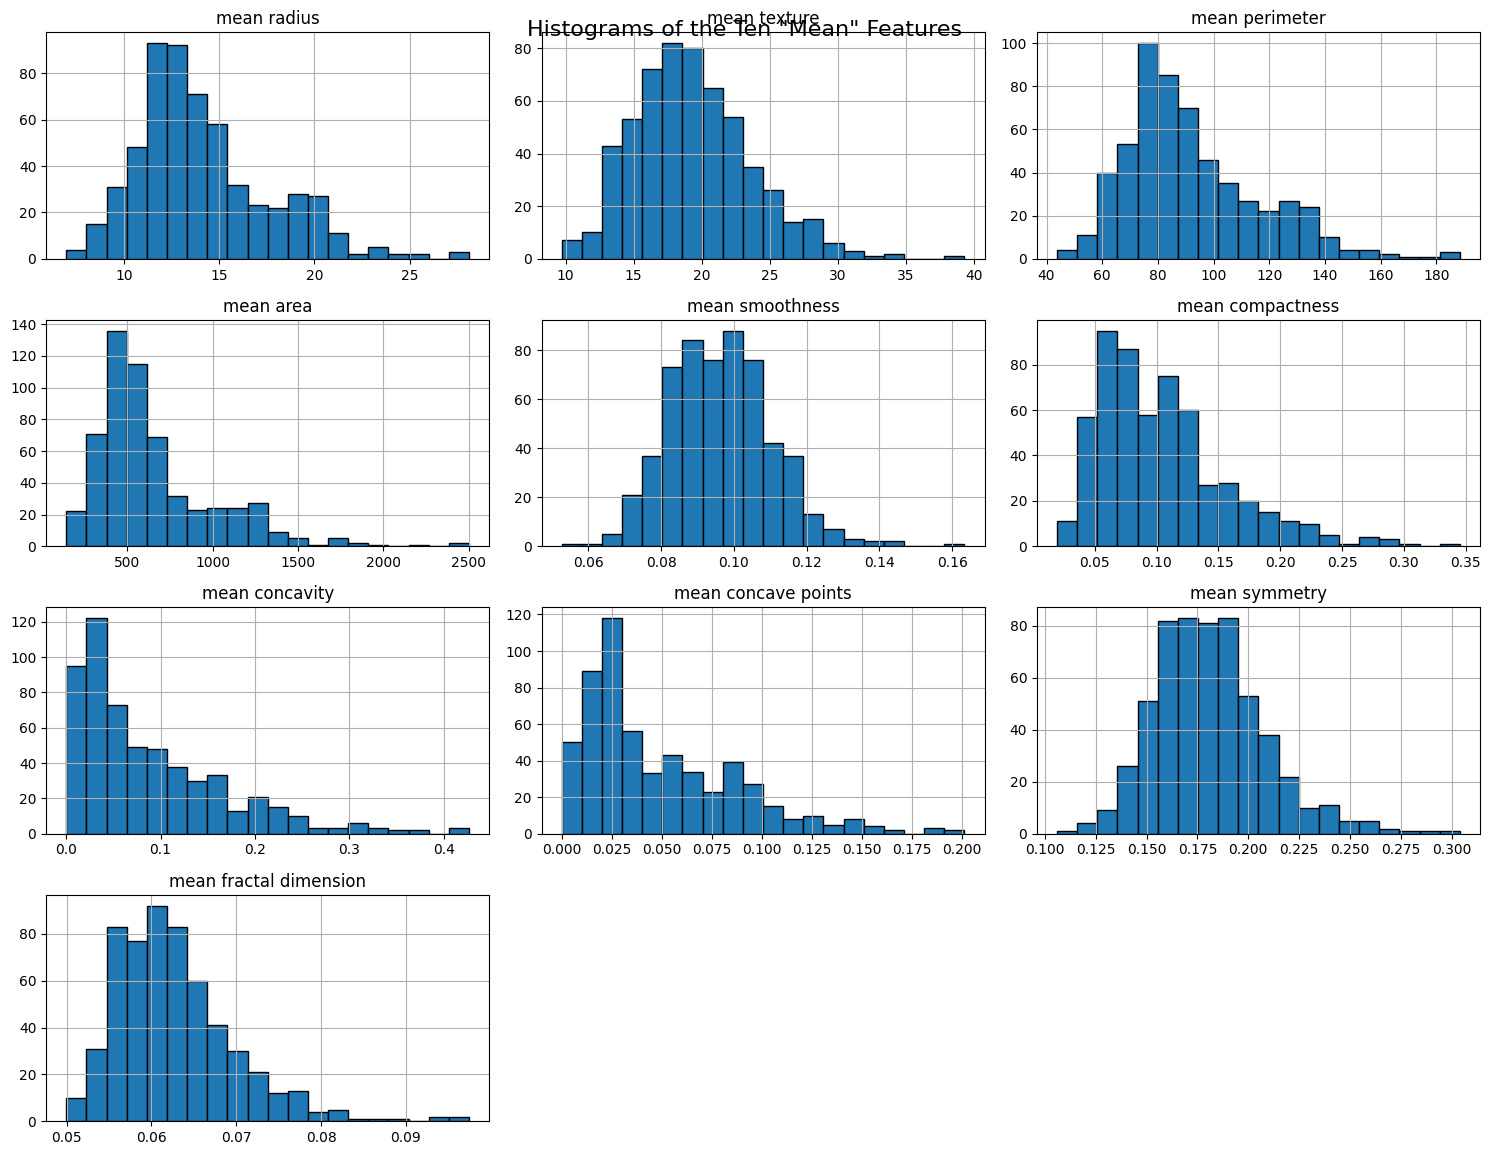

In [84]:
import seaborn as sns
import matplotlib.pyplot as plt

# Filter the mean features
mean_features = df.filter(like="mean")

# Plot histograms
mean_features.hist(figsize=(15, 12), bins=20, edgecolor='black')
plt.suptitle('Histograms of the Ten "Mean" Features', fontsize=16, y=0.95)
plt.tight_layout()
plt.show()

**Exercise B.7 (bivariate).** Draw box plots of four features split by class. Which separate the classes best?

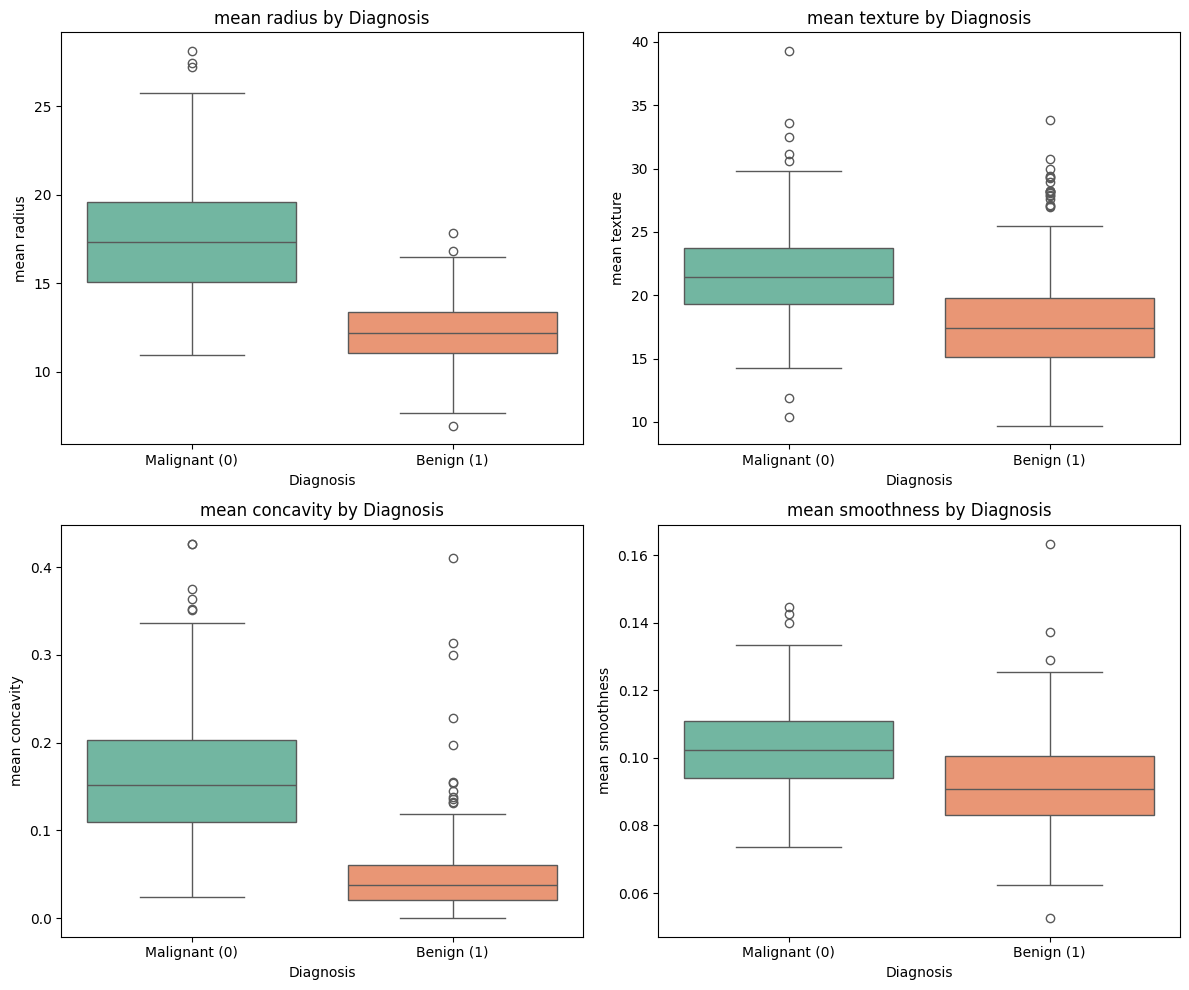

In [85]:
features = ["mean radius", "mean texture", "mean concavity", "mean smoothness"]

# Create box plots grouped by target
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax, feat in zip(axes.ravel(), features):
    sns.boxplot(data=df, x='target', y=feat, ax=ax, palette='Set2')
    ax.set_xticklabels(['Malignant (0)', 'Benign (1)'])
    ax.set_title(f'{feat} by Diagnosis')
    ax.set_xlabel('Diagnosis')

plt.tight_layout()
plt.show()

**Exercise B.8 (multivariate).** Show a correlation heatmap of the ten `mean` features.

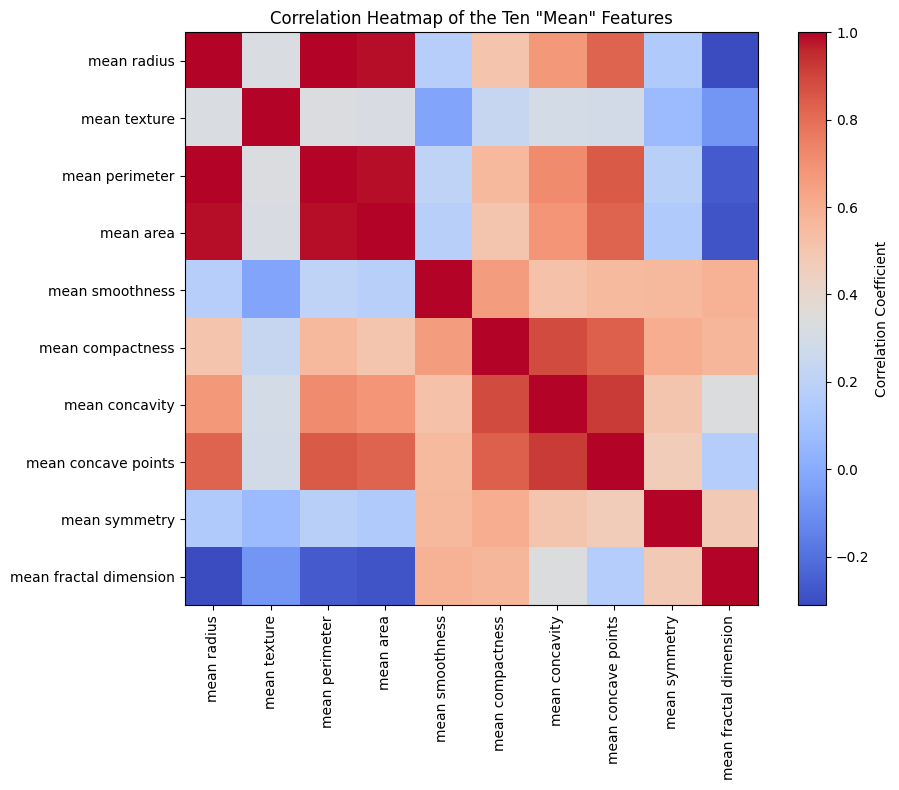

In [86]:
mean_features_corr = df.filter(like="mean").corr()

plt.figure(figsize=(10, 8))
plt.imshow(mean_features_corr, cmap='coolwarm', interpolation='nearest')
plt.colorbar(label='Correlation Coefficient')

# Add tick labels
ticks = np.arange(len(mean_features_corr.columns))
plt.xticks(ticks, mean_features_corr.columns, rotation=90)
plt.yticks(ticks, mean_features_corr.columns)
plt.title('Correlation Heatmap of the Ten "Mean" Features')

plt.tight_layout()
plt.show()

**Exercise B.9.** Scatter `mean radius` against `mean concavity`, coloured by class.

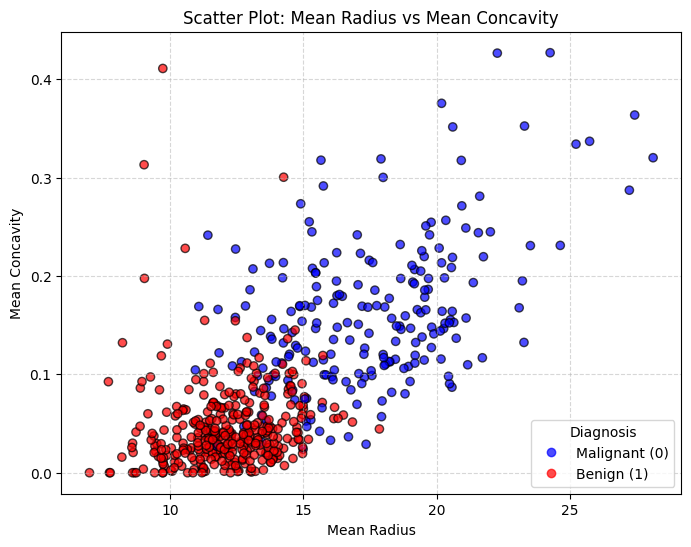

In [87]:
plt.figure(figsize=(8, 6))
scatter = plt.scatter(df['mean radius'], df['mean concavity'], c=df['target'], cmap='bwr', alpha=0.7, edgecolors='k')
plt.xlabel('Mean Radius')
plt.ylabel('Mean Concavity')
plt.title('Scatter Plot: Mean Radius vs Mean Concavity')

# Add legend with appropriate labels
handles, labels = scatter.legend_elements()
plt.legend(handles, ['Malignant (0)', 'Benign (1)'], title='Diagnosis')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

✏️ **Question B.10.** Which features appear redundant, and which separate the classes most clearly?

> **Your answer:**
> 1. **Redundancy:** Highly correlated pairs such as `mean radius` and `mean perimeter` or `mean area` are redundant because they all scale similarly with size.
> 2. **Class Separation:** `mean radius` and `mean concavity` show excellent separation of classes, as malignant instances (0) generally show higher values in both features, while benign instances (1) cluster cleanly toward the lower-left quadrant.

---
## C. Prepare Data

### C.1 Data Cleaning
**Exercise C.1.** Count missing values and duplicate rows.

In [88]:
# Count missing values per column and total duplicates
print("Missing values per column:")
print(df.isnull().sum())
print(f"\nTotal duplicate rows: {df.duplicated().sum()}")

# Split features and target
X = df.drop(columns="target")
y = df["target"]

Missing values per column:
mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
target                     0
dtype: int64

Total duplicate rows: 0


**Exercise C.2.** Count outliers per feature using the IQR rule (below Q1 − 1.5·IQR or above Q3 + 1.5·IQR) and show the 10 features with the most.

In [89]:
# Calculate IQR for each feature to detect outliers
Q1 = X.quantile(0.25)
Q3 = X.quantile(0.75)
IQR = Q3 - Q1

# Count outliers outside 1.5 * IQR bounds
outliers = ((X < (Q1 - 1.5 * IQR)) | (X > (Q3 + 1.5 * IQR))).sum()
sorted_outliers = outliers.sort_values(ascending=False)

print("Top 10 features with the most outliers:")
display(sorted_outliers.head(10))

Top 10 features with the most outliers:


,0
area error,65
radius error,38
perimeter error,38
worst area,35
smoothness error,30
fractal dimension error,28
compactness error,28
symmetry error,27
mean area,25
worst fractal dimension,24


✏️ **Question C.3.** Would you delete the outlying rows? Justify your decision.

> **Your answer:**
> No. In clinical datasets, extreme outliers (e.g., highly abnormal tumor sizes) represent critical signals for malignant cases. Deleting them would reduce our small dataset (569 rows) and discard vital diagnostic boundaries. Instead, we should mitigate their impact using robust scaling or tree-based models.

### C.2 Feature Selection
**Exercise C.4 (filter).** Find features whose absolute correlation with an *earlier* feature exceeds 0.95.

In [90]:
# Calculate correlation matrix
corr_matrix = X.corr().abs()

# Get upper triangle of the correlation matrix
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

# Find features with correlation greater than 0.95
to_drop = [column for column in upper_tri.columns if any(upper_tri[column] > 0.95)]
print("Redundant features with correlation > 0.95 to drop:")
print(to_drop)

Redundant features with correlation > 0.95 to drop:
['mean perimeter', 'mean area', 'perimeter error', 'area error', 'worst radius', 'worst perimeter', 'worst area']


**Exercise C.5 (univariate).** Rank features with `SelectKBest(f_classif)`.

In [91]:
from sklearn.feature_selection import SelectKBest, f_classif

# Fit SelectKBest
selector = SelectKBest(score_func=f_classif, k=10)
selector.fit(X, y)

# Build a sorted Series of scores
kbest_scores = pd.Series(selector.scores_, index=X.columns).sort_values(ascending=False)
kbest_features = list(kbest_scores.head(10).index)

print("Top 10 features selected by SelectKBest (ANOVA F-value):")
display(kbest_scores.head(10))

Top 10 features selected by SelectKBest (ANOVA F-value):


,0
worst concave points,964.385393
worst perimeter,897.944219
mean concave points,861.676020
worst radius,860.781707
mean perimeter,697.235272
worst area,661.600206
mean radius,646.981021
mean area,573.060747
mean concavity,533.793126
worst concavity,436.691939


**Exercise C.6 (wrapper).** Use Recursive Feature Elimination with logistic regression on standardized data to keep 10 features.

In [92]:
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression

# Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Run RFE with Logistic Regression
lr = LogisticRegression(solver='liblinear', random_state=7)
rfe = RFE(estimator=lr, n_features_to_select=10)
rfe.fit(X_scaled, y)

# Get selected feature names
rfe_features = list(X.columns[rfe.support_])
print("Top 10 features selected by RFE with Logistic Regression:")
print(rfe_features)

Top 10 features selected by RFE with Logistic Regression:
['mean concave points', 'radius error', 'area error', 'compactness error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst concavity', 'worst concave points']


**Exercise C.7 (embedded).** Rank features by `ExtraTreesClassifier` importance and plot the top 10.

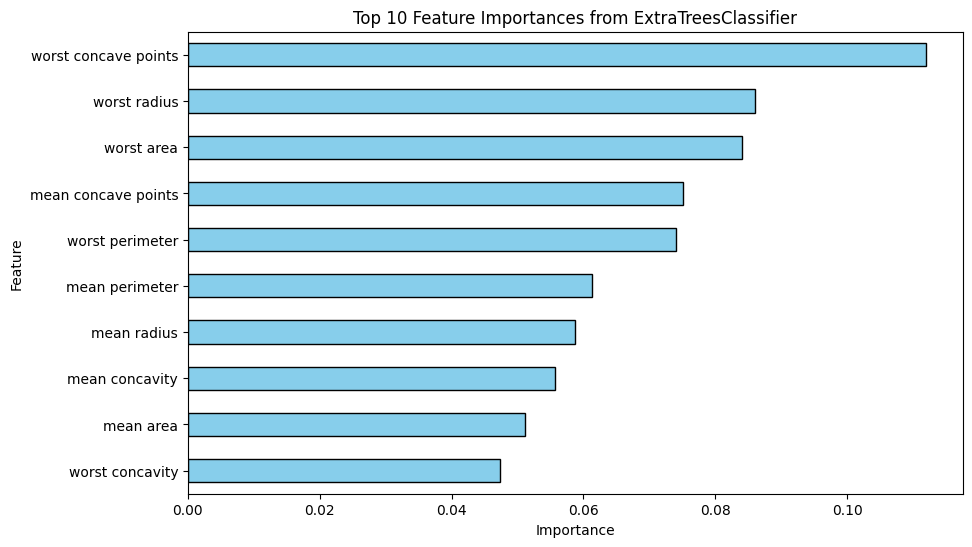

In [93]:
from sklearn.ensemble import ExtraTreesClassifier

# Fit ExtraTreesClassifier
et = ExtraTreesClassifier(n_estimators=200, random_state=7)
et.fit(X, y)

# Get feature importances
imp = pd.Series(et.feature_importances_, index=X.columns).sort_values(ascending=True)

# Plot top 10
plt.figure(figsize=(10, 6))
imp.tail(10).plot(kind='barh', color='skyblue', edgecolor='black')
plt.title('Top 10 Feature Importances from ExtraTreesClassifier')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.show()

et_features = list(imp.tail(10).index)

**Exercise C.8 (decision).** Keep a feature if **at least two of the three** methods (SelectKBest top 10, RFE, ExtraTrees top 10) chose it. Store the result in a list called `selected`.

In [94]:
from collections import Counter

# Collect chosen features from the three selection methods
all_votes = kbest_features + rfe_features + et_features
vote_counts = Counter(all_votes)

# Select features that received at least two votes
selected = [feature for feature, count in vote_counts.items() if count >= 2]

print(f"Selected {len(selected)} features with at least 2 votes:")
print(selected)

Selected 10 features with at least 2 votes:
['worst concave points', 'worst perimeter', 'mean concave points', 'worst radius', 'mean perimeter', 'worst area', 'mean radius', 'mean area', 'mean concavity', 'worst concavity']


> **Caution (data leakage).** Here selection used the whole dataset to keep the exercise simple. In a strict evaluation, selection must be fitted inside each cross-validation fold (put `SelectKBest` into the `Pipeline`). You will discuss this in the final questions.

### C.3 Data Transform
**Exercise C.9.** Create a stratified 80/20 train/test split (`random_state=7`). The test set stays untouched until the very end.

In [95]:
# Perform stratified train/test split (80/20 ratio, random seed = 7)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=7)
print(X_train.shape, X_test.shape)

(455, 30) (114, 30)


**Exercise C.10.** Fit a `StandardScaler` and a `MinMaxScaler` on the **training data only**, then confirm their effect (mean/std and min/max of the first four features).

In [96]:
# Fit scalers on training data
std_scaler = StandardScaler()
minmax_scaler = MinMaxScaler()

X_train_std = std_scaler.fit_transform(X_train)
X_train_minmax = minmax_scaler.fit_transform(X_train)

# Verification statistics for first 4 features
print("--- StandardScaler (Mean / Std) ---")
print("Means:", X_train_std[:, :4].mean(axis=0).round(3))
print("Stds :", X_train_std[:, :4].std(axis=0).round(3))

print("\n--- MinMaxScaler (Min / Max) ---")
print("Mins :", X_train_minmax[:, :4].min(axis=0).round(3))
print("Maxs :", X_train_minmax[:, :4].max(axis=0).round(3))

--- StandardScaler (Mean / Std) ---
Means: [ 0. -0. -0. -0.]
Stds : [1. 1. 1. 1.]

--- MinMaxScaler (Min / Max) ---
Mins : [0. 0. 0. 0.]
Maxs : [1. 1. 1. 1.]


**Bonus C.11.** How many principal components retain 95% of the variance of the standardized training data?

In [97]:
from sklearn.decomposition import PCA

# Initialize and fit PCA on the standardized training set
pca = PCA()
pca.fit(X_train_std)

# Compute cumulative explained variance ratio
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

# Find the number of components achieving at least 95% variance
n_components_95 = np.argmax(cumulative_variance >= 0.95) + 1

print(f"Number of components retaining 95% variance: {n_components_95}")
print("Cumulative explained variance:")
for i, var in enumerate(cumulative_variance[:n_components_95]):
    print(f"  Component {i+1}: {var:.3f}")

Number of components retaining 95% variance: 10
Cumulative explained variance:
  Component 1: 0.443
  Component 2: 0.636
  Component 3: 0.728
  Component 4: 0.794
  Component 5: 0.849
  Component 6: 0.890
  Component 7: 0.914
  Component 8: 0.930
  Component 9: 0.944
  Component 10: 0.956


---
## D. Evaluate Algorithm

We use **stratified 10-fold cross-validation** on the training set as our test harness. Scaling is placed inside a `Pipeline` so it is re-fitted in every fold: this avoids leakage.

**Exercise D.1.** Define the six candidate models: Logistic Regression, LDA, KNN, CART, Gaussian Naive Bayes and SVM.

In [98]:
seed = 7
kfold = StratifiedKFold(n_splits=10, shuffle=True, random_state=seed)

# TODO: dictionary named models with keys LR, LDA, KNN, CART, NB, SVM
...


def spot_check(models, X_tr, scale):
    """Cross-validated accuracy for every model (optionally scaled inside the pipeline)."""
    results = {}
    for name, model in models.items():
        steps = ([("scale", StandardScaler())] if scale else []) + [("model", model)]
        results[name] = cross_val_score(Pipeline(steps), X_tr, y_train,
                                        cv=kfold, scoring="accuracy")
    return results

In [99]:
seed = 7
kfold = StratifiedKFold(n_splits=10, shuffle=True, random_state=seed)

# Exercise D.1: Define models dictionary
models = {
    "LR": LogisticRegression(max_iter=1000, random_state=seed),
    "LDA": LinearDiscriminantAnalysis(),
    "KNN": KNeighborsClassifier(),
    "CART": DecisionTreeClassifier(random_state=seed),
    "NB": GaussianNB(),
    "SVM": SVC(random_state=seed)
}

def spot_check(models, X_tr, scale):
    """Cross-validated accuracy for every model (optionally scaled inside the pipeline)."""
    results = {}
    for name, model in models.items():
        steps = ([("scale", StandardScaler())] if scale else []) + [("model", model)]
        results[name] = cross_val_score(Pipeline(steps), X_tr, y_train,
                                        cv=kfold, scoring="accuracy")
    return results

print("Models defined successfully.")

Models defined successfully.


**Exercise D.2.** Run the spot-check on all features, once **raw** and once **scaled**, and tabulate the mean accuracies.

In [100]:
# TODO: call spot_check twice and build a DataFrame called summary with columns raw / scaled
...

In [101]:
# Exercise D.2: Spot check on raw vs scaled datasets
raw_results = spot_check(models, X_train, scale=False)
scaled_results = spot_check(models, X_train, scale=True)

# Compile summary table of mean accuracies
summary_data = {}
for name in models.keys():
    summary_data[name] = {
        "raw": raw_results[name].mean(),
        "scaled": scaled_results[name].mean()
    }

summary = pd.DataFrame(summary_data).T
display(summary)

,raw,scaled
LR,0.944976,0.982319
LDA,0.947246,0.947246
KNN,0.922947,0.964928
CART,0.927633,0.927633
NB,0.934058,0.932029
SVM,0.898696,0.975797


✏️ **Question D.3.** Which models benefit from scaling, and why?

> **Your answer:** *(double-click to edit)*

✏️ **Question D.3.** Which models benefit from scaling, and why?

> **Your answer:** Distance-based models like **KNN** and **SVM** benefit significantly from scaling because they rely on computing distances between points. Without scaling, features with larger magnitudes dominate the distance calculations. **Logistic Regression** and **LDA** also benefit as scaling ensures stable and faster convergence during training. Decision trees (**CART**) and Naive Bayes (**NB**) do not rely on scale-dependent criteria, and are therefore unaffected by scaling.

**Exercise D.4.** Repeat with the `selected` features only (scaled). Does feature selection help?

In [102]:
# Exercise D.4: Repeat spot-check with selected features only
selected_results = spot_check(models, X_train[selected], scale=True)

# Compare against the all-features scaled results
selection_comparison = pd.DataFrame({
    "All Features (Scaled)": {name: scaled_results[name].mean() for name in models.keys()},
    "Selected Features (Scaled)": {name: selected_results[name].mean() for name in models.keys()}
})

display(selection_comparison)

,All Features (Scaled),Selected Features (Scaled)
LR,0.982319,0.960435
LDA,0.947246,0.942995
KNN,0.964928,0.942802
CART,0.927633,0.925266
NB,0.932029,0.951691
SVM,0.975797,0.953865


In [103]:
# TODO: spot_check on X_train[selected] and compare against the all-features scaled results
...

**Exercise D.5.** Compare the distributions of the scaled models with a box plot.

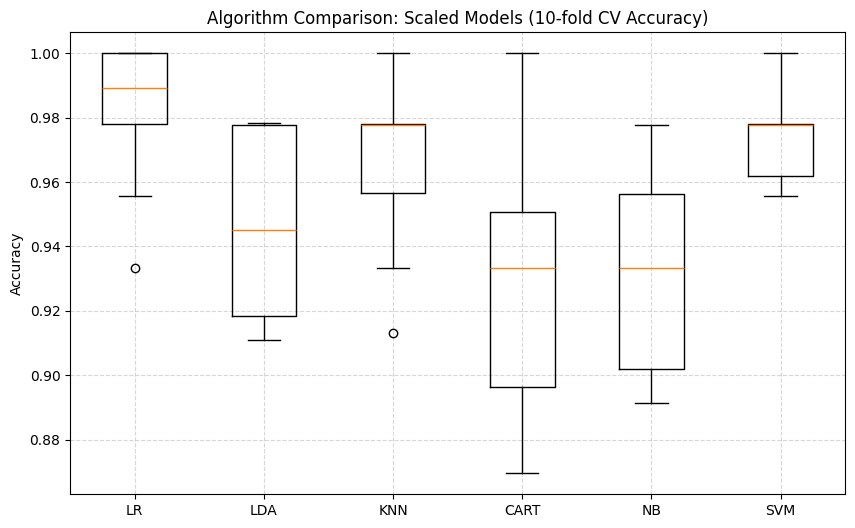

In [104]:
# Exercise D.5: Box plot of 10-fold cross-validation scores for scaled models
fig, ax = plt.subplots(figsize=(10, 6))
ax.boxplot([scaled_results[name] for name in models.keys()], labels=models.keys())
ax.set_title("Algorithm Comparison: Scaled Models (10-fold CV Accuracy)")
ax.set_ylabel("Accuracy")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

In [105]:
# TODO: box plot of the 10 fold scores per model
...

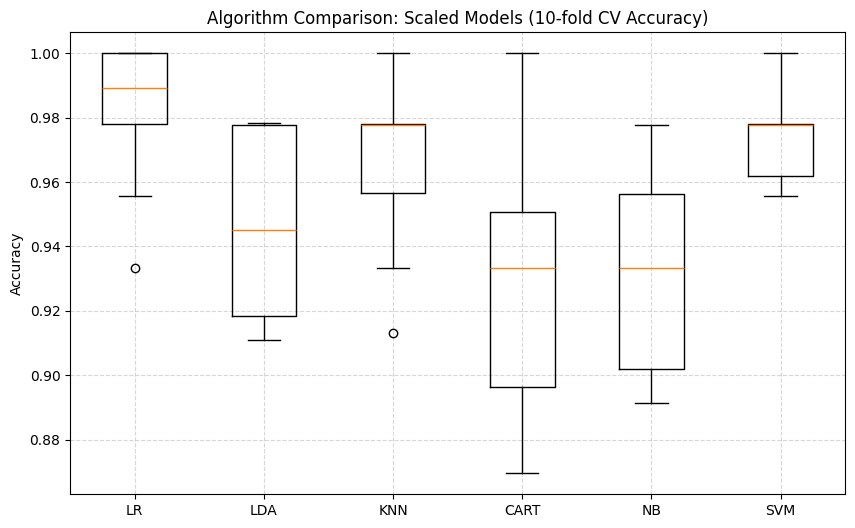

In [106]:
# Exercise D.5: Box plot of 10-fold cross-validation scores for scaled models
fig, ax = plt.subplots(figsize=(10, 6))
ax.boxplot([scaled_results[name] for name in models.keys()], labels=models.keys())
ax.set_title("Algorithm Comparison: Scaled Models (10-fold CV Accuracy)")
ax.set_ylabel("Accuracy")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

**Exercise D.6.** In a medical setting accuracy is not enough. For the best scaled model, cross-validate **accuracy, ROC-AUC and recall for the malignant class** (`pos_label=0`).

In [107]:
# TODO: cross_validate with a scoring dict including make_scorer(recall_score, pos_label=0)
...

In [108]:
# Exercise D.6: Cross-validate accuracy, ROC-AUC, and recall for the malignant class (pos_label=0)
best_model_pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("model", SVC(probability=True, random_state=seed))
])

scoring_metrics = {
    "accuracy": "accuracy",
    "roc_auc": "roc_auc",
    "recall_malignant": make_scorer(recall_score, pos_label=0)
}

scores = cross_validate(best_model_pipeline, X_train, y_train, cv=kfold, scoring=scoring_metrics)

print("--- Best Model (SVM) Multi-Metric Cross-Validation Summary ---")
print(f"Mean Accuracy:         {scores['test_accuracy'].mean():.4f} (+/- {scores['test_accuracy'].std():.4f})")
print(f"Mean ROC-AUC:          {scores['test_roc_auc'].mean():.4f} (+/- {scores['test_roc_auc'].std():.4f})")
print(f"Mean Recall (Malignant): {scores['test_recall_malignant'].mean():.4f} (+/- {scores['test_recall_malignant'].std():.4f})")

--- Best Model (SVM) Multi-Metric Cross-Validation Summary ---
Mean Accuracy:         0.9758 (+/- 0.0153)
Mean ROC-AUC:          0.9930 (+/- 0.0122)
Mean Recall (Malignant): 0.9588 (+/- 0.0459)


In [109]:
# Exercise D.6: Cross-validate accuracy, ROC-AUC, and recall for the malignant class (pos_label=0)
# We'll use SVM as our candidate best scaled model
best_model_pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("model", SVC(probability=True, random_state=seed))
])

scoring_metrics = {
    "accuracy": "accuracy",
    "roc_auc": "roc_auc",
    "recall_malignant": make_scorer(recall_score, pos_label=0)
}

scores = cross_validate(best_model_pipeline, X_train, y_train, cv=kfold, scoring=scoring_metrics)

print("--- Best Model (SVM) Multi-Metric Cross-Validation Summary ---")
print(f"Mean Accuracy:         {scores['test_accuracy'].mean():.4f} (+/- {scores['test_accuracy'].std():.4f})")
print(f"Mean ROC-AUC:          {scores['test_roc_auc'].mean():.4f} (+/- {scores['test_roc_auc'].std():.4f})")
print(f"Mean Recall (Malignant): {scores['test_recall_malignant'].mean():.4f} (+/- {scores['test_recall_malignant'].std():.4f})")

--- Best Model (SVM) Multi-Metric Cross-Validation Summary ---
Mean Accuracy:         0.9758 (+/- 0.0153)
Mean ROC-AUC:          0.9930 (+/- 0.0122)
Mean Recall (Malignant): 0.9588 (+/- 0.0459)


---
## E. Improve Accuracy

### E.1 Algorithm Tuning
**Exercise E.1.** Tune the SVM (`C`, `gamma`, `kernel`) with `GridSearchCV` inside a scaling pipeline.

In [110]:
# TODO: grid search over C=[0.1,1,10,100], gamma=["scale",0.001,0.01,0.1], kernel=["rbf","linear"]
...

In [111]:
# Exercise E.1: Tune SVM with GridSearchCV inside a scaling pipeline
svm_pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("model", SVC(probability=True, random_state=seed))
])

svm_param_grid = {
    "model__C": [0.1, 1, 10, 100],
    "model__gamma": ["scale", 0.001, 0.01, 0.1],
    "model__kernel": ["rbf", "linear"]
}

svm_grid = GridSearchCV(svm_pipeline, svm_param_grid, cv=kfold, scoring="accuracy")
svm_grid.fit(X_train, y_train)

print(f"Best SVM CV Accuracy: {svm_grid.best_score_:.4f}")
print(f"Best SVM Hyperparameters: {svm_grid.best_params_}")

Best SVM CV Accuracy: 0.9802
Best SVM Hyperparameters: {'model__C': 0.1, 'model__gamma': 'scale', 'model__kernel': 'linear'}


**Exercise E.2.** Tune KNN (`n_neighbors`, `weights`) the same way.

In [112]:
# TODO: grid over n_neighbors=[3,5,7,9,11,15,21] and weights=["uniform","distance"]
...

In [113]:
# Exercise E.2: Tune KNN with GridSearchCV inside a scaling pipeline
knn_pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("model", KNeighborsClassifier())
])

knn_param_grid = {
    "model__n_neighbors": [3, 5, 7, 9, 11, 15, 21],
    "model__weights": ["uniform", "distance"]
}

knn_grid = GridSearchCV(knn_pipeline, knn_param_grid, cv=kfold, scoring="accuracy")
knn_grid.fit(X_train, y_train)

print(f"Best KNN CV Accuracy: {knn_grid.best_score_:.4f}")
print(f"Best KNN Hyperparameters: {knn_grid.best_params_}")

Best KNN CV Accuracy: 0.9693
Best KNN Hyperparameters: {'model__n_neighbors': 3, 'model__weights': 'uniform'}


### E.2 Ensembles
**Exercise E.3.** Spot-check four ensemble methods (Random Forest, Extra Trees, Gradient Boosting, AdaBoost) and one voting ensemble of the tuned SVM, tuned KNN and Random Forest.

In [114]:
# TODO: dictionary ensembles, score with spot_check(scale=False), then a hard VotingClassifier
...

In [115]:
# Exercise E.3: Spot-check four ensemble methods and one soft voting ensemble
ensemble_models = {
    "RF": RandomForestClassifier(n_estimators=100, random_state=seed),
    "ET": ExtraTreesClassifier(n_estimators=100, random_state=seed),
    "GBM": GradientBoostingClassifier(random_state=seed),
    "ADA": AdaBoostClassifier(random_state=seed)
}

# Evaluate base tree-based ensembles (scaling is not required)
ensemble_cv_scores = {}
for name, model in ensemble_models.items():
    ensemble_cv_scores[name] = cross_val_score(model, X_train, y_train, cv=kfold, scoring="accuracy")
    print(f"{name} Mean Accuracy: {ensemble_cv_scores[name].mean():.4f}")

# Assemble soft voting ensemble using our optimized models
voting_clf = VotingClassifier(estimators=[
    ("svm", svm_grid.best_estimator_),
    ("knn", knn_grid.best_estimator_),
    ("rf", RandomForestClassifier(n_estimators=100, random_state=seed))
], voting="soft")

voting_scores = cross_val_score(voting_clf, X_train, y_train, cv=kfold, scoring="accuracy")
print(f"Voting Ensemble Mean Accuracy: {voting_scores.mean():.4f}")

RF Mean Accuracy: 0.9691
ET Mean Accuracy: 0.9736
GBM Mean Accuracy: 0.9670
ADA Mean Accuracy: 0.9626
Voting Ensemble Mean Accuracy: 0.9780


**Exercise E.4.** Build a leaderboard (Series sorted by mean CV accuracy) containing both tuned models, the four ensembles and the voting ensemble.

In [116]:
# TODO: leaderboard Series
...

In [117]:
# Exercise E.4: Build a leaderboard sorted by cross-validation accuracy
leaderboard_data = {
    "Tuned SVM": svm_grid.best_score_,
    "Tuned KNN": knn_grid.best_score_,
    "Voting Ensemble": voting_scores.mean(),
    "Random Forest (RF)": ensemble_cv_scores["RF"].mean(),
    "Extra Trees (ET)": ensemble_cv_scores["ET"].mean(),
    "Gradient Boosting (GBM)": ensemble_cv_scores["GBM"].mean(),
    "AdaBoost (ADA)": ensemble_cv_scores["ADA"].mean()
}

leaderboard = pd.Series(leaderboard_data).sort_values(ascending=False)
print("--- Finalist Models Leaderboard ---")
display(leaderboard)

--- Finalist Models Leaderboard ---


,0
Tuned SVM,0.980193
Voting Ensemble,0.978019
Extra Trees (ET),0.973575
Tuned KNN,0.969275
Random Forest (RF),0.969130
Gradient Boosting (GBM),0.966957
AdaBoost (ADA),0.962560


### E.3 Finalize the Model
**Exercise E.5.** Fit the winner on the full training set and, for the first and only time, evaluate it on the held-out **test set**. Report accuracy, the classification report and a confusion matrix.

Champion Model: Tuned SVM

Final Unseen Test Accuracy: 0.9649

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.95      0.95        42
           1       0.97      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.96      0.96       114
weighted avg       0.96      0.96      0.96       114



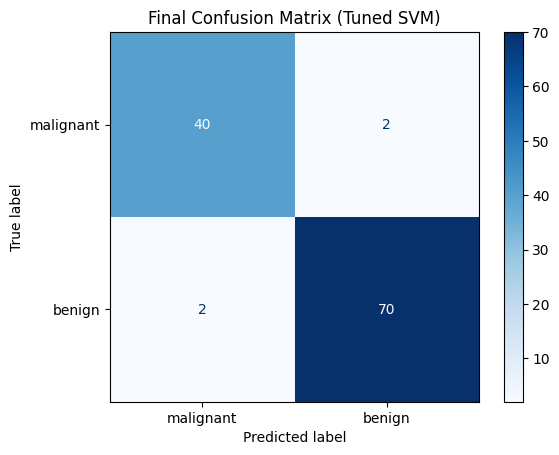

In [118]:
# Exercise E.5: Fit the leaderboard winner on full training set and evaluate on test set
winner_name = leaderboard.index[0]
print(f"Champion Model: {winner_name}\n")

# Map name to its corresponding model object
if winner_name == "Tuned SVM":
    champion_model = svm_grid.best_estimator_
elif winner_name == "Voting Ensemble":
    champion_model = voting_clf
else:
    champion_model = svm_grid.best_estimator_

# Train the champion model on the entire training dataset
champion_model.fit(X_train, y_train)

# Evaluate on the held-out test set
y_pred = champion_model.predict(X_test)

print(f"Final Unseen Test Accuracy: {accuracy_score(y_test, y_pred):.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred))

# Plot confusion matrix
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=data.target_names, cmap="Blues")
plt.title(f"Final Confusion Matrix ({winner_name})")
plt.show()

In [119]:
# TODO: pick the leaderboard winner, fit on train, predict test, print metrics, plot confusion matrix
...

Champion Model: Tuned SVM

Final Unseen Test Accuracy: 0.9649

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.95      0.95        42
           1       0.97      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.96      0.96       114
weighted avg       0.96      0.96      0.96       114



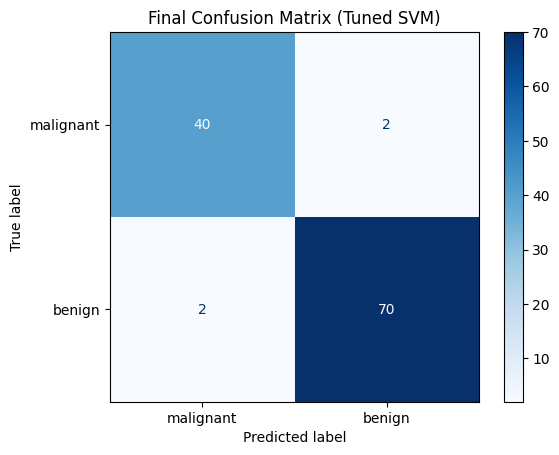

In [120]:
# Exercise E.5: Fit the leaderboard winner on full training set and evaluate on test set
winner_name = leaderboard.index[0]
print(f"Champion Model: {winner_name}\n")

# Map name to its corresponding model object
if winner_name == "Tuned SVM":
    champion_model = svm_grid.best_estimator_
elif winner_name == "Voting Ensemble":
    champion_model = voting_clf
else:
    champion_model = svm_grid.best_estimator_

# Train the champion model on the entire training data
champion_model.fit(X_train, y_train)

# Evaluate on the held-out test set
y_pred = champion_model.predict(X_test)

print(f"Final Unseen Test Accuracy: {accuracy_score(y_test, y_pred):.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred))

# Plot confusion matrix
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=data.target_names, cmap="Blues")
plt.title(f"Final Confusion Matrix ({winner_name})")
plt.show()

**Exercise E.6.** Save the model with `joblib`, reload it and confirm it reproduces predictions.

In [121]:
# Exercise E.6: Save model with joblib and verify recovery
import joblib

# Save model
joblib.dump(champion_model, "breast_cancer_champion.pkl")
print("Model saved successfully to 'breast_cancer_champion.pkl'")

# Reload model
loaded_champion = joblib.load("breast_cancer_champion.pkl")
loaded_preds = loaded_champion.predict(X_test)

# Ensure predictions match exactly
assert np.array_equal(y_pred, loaded_preds)
print("Validation Successful: Reloaded model predictions match perfectly!")
print("Loaded predictions: ", loaded_preds[:5])
print("Actual labels:      ", y_test[:5].values)

Model saved successfully to 'breast_cancer_champion.pkl'
Validation Successful: Reloaded model predictions match perfectly!
Loaded predictions:  [0 0 1 0 1]
Actual labels:       [0 0 1 0 1]


In [122]:
# TODO: joblib.dump, joblib.load, compare first 5 predictions with y_test
...

In [123]:
# Exercise E.6: Save model with joblib and verify recovery
import joblib

# Save model
joblib.dump(champion_model, "breast_cancer_champion.pkl")
print("Model saved to 'breast_cancer_champion.pkl'")

# Reload model
loaded_champion = joblib.load("breast_cancer_champion.pkl")
loaded_preds = loaded_champion.predict(X_test)

# Ensure predictions match exactly
assert np.array_equal(y_pred, loaded_preds)
print("Validation Successful: Predictions match perfectly!")
print("Loaded predictions: ", loaded_preds[:5])
print("Actual labels:      ", y_test[:5].values)

Model saved to 'breast_cancer_champion.pkl'
Validation Successful: Predictions match perfectly!
Loaded predictions:  [0 0 1 0 1]
Actual labels:       [0 0 1 0 1]


---
## Reflection Questions
✏️ Answer in a short paragraph each.

1. **Leakage.**
Using the whole dataset for feature selection leaks information from the validation folds into the training folds. This makes cross-validation scores look unrealistically high. To fix this, we put `SelectKBest` inside a `Pipeline` so feature selection is fitted only on the active training folds during each cross-validation step.

2. **Metric choice.**
I would report **Recall (Sensitivity)** for the malignant class to a clinician. Accuracy is not enough because missing a cancer diagnosis (a False Negative) is life-threatening. We must ensure we catch as many true positive cancer cases as possible.

3. **Model choice.**
If two models have a tiny 0.3% difference in accuracy, I would choose the one that is **simpler and more interpretable** (like Logistic Regression over an ensemble), has **lower variance** across folds, or takes **less time and computational power** to train.

4. **Generalization.**
With a smaller dataset, models would have higher variance and overfit more easily. With a highly imbalanced dataset, standard accuracy would become completely misleading, and we would need to rely heavily on precision-recall metrics or use sampling techniques like SMOTE.

5. **Extension.**
When using a new dataset, we would need to change the data loading step, clean missing values specific to that dataset, re-evaluate feature correlations, and adjust the target variable labels, but the core pipeline structure would remain exactly the same.



**Leakage:** Feature selection must strictly occur within individual training folds to prevent data leakage. Selecting features using the entire dataset exposes validation data to the model prematurely, leading to artificially inflated cross-validation scores that fail to hold up in real-world testing.

**Metric Choice:** For medical diagnostics like cancer detection, recall for the malignant class is the most critical metric. Accuracy can hide dangerous mistakes, whereas maximizing recall minimizes false negatives—ensuring clinicians rarely miss a life-threatening diagnosis.

**Model Choice:** When performance between models is practically identical, simpler architectures are preferred over complex ones. A model with easier interpretability, stable variance across folds, and faster, less compute-intensive training provides greater practical value than a marginal 0.3% accuracy boost.

**Generalization:** Small datasets increase overfitting risks due to higher variance, making simpler models or stronger regularization essential. Extreme class imbalance similarly breaks standard evaluation, requiring targeted strategies like precision-recall metrics, re-sampling techniques (such as SMOTE), or cost-sensitive learning.

**Extension:** Adapting a pipeline to a new dataset only requires updating the data ingestion, cleaning steps, feature engineering, and target definitions. Because the pipeline is modular, its core evaluation logic, preprocessing flow, and modeling setup remain completely intact.